# MUC02 — Credit Pre-Screening Engine
## Loan Intake Optimisation

**Industry:** BFSI — Retail Lending

**Objective:** Analyse historical personal-loan decisions and develop a credit pre-screening model that helps reduce manual review workload while controlling the risk of incorrect automated decisions.

**Business Problem:**

The bank receives approximately 3,000 personal-loan applications each month. Each application takes an analyst around 25 minutes to review. The bank wants to use historical credit decisions to identify applications suitable for automated routing while ensuring that uncertain applications continue to receive human review.

**Dataset:** MUC02_Credit_PreScreening_Dataset.csv

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn and Scikit-learn.

# CBIM Problem Canvas — Credit Pre-Screening Engine

| Canvas Element | Your Answer |
|---|---|
| **Situation (S)** | A mid-size private bank offers unsecured personal loans across India and receives approximately 3,000 applications per month. Currently, credit analysts manually review each application, taking around 25 minutes per review. |
| **Complication (C)** | Manual reviews consume significant analyst time and slow down loan processing. Analysts spend time reviewing applications that may have clear-cut outcomes, while applicants may experience delays and incorrect decisions could unfairly reject creditworthy customers. |
| **Question (Q)** | How can the bank use six months of historical credit decisions to identify applications for safe auto-decline or fast-track processing, while sending uncertain applications to human analysts? |
| **SSOT (Single Source of Truth)** | The provided MUC02_Credit_PreScreening_Dataset.csv is the single source of truth. The decision column represents the final historical decision made by the bank's credit team: **Approved** or **Declined**. |
| **Success Definition** | The pre-screener should satisfy two risk limits: no more than **5% of auto-declined applications** should have been historically Approved, and no more than **5% of fast-tracked applications** should have been historically Declined. It should also reduce manual reviews and quantify analyst hours saved. |
| **Primary Stakeholder** | The primary stakeholder is the **Credit Policy Analyst**, who will recommend the model and thresholds to the Head of Retail Lending. Credit analysts, loan applicants, and the bank are also affected by the decision. |

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn jupyter

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


## 5.1 Load, Inspect and Clean

The objective of this step is to understand the dataset's structure, identify missing values, calculate the overall approval rate, and investigate potential data-quality issues. Special attention is given to missing monthly income, missing credit scores, and unusually large monthly income values. Each cleaning decision will be documented and justified before proceeding to further analysis.

In [2]:
import pandas as pd
import numpy as np

# Load the dataset (CSV sits in the same folder as this notebook)
df = pd.read_csv("MUC02_Credit_PreScreening_Dataset.csv")

# Display the first five rows
df.head()

,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


In [3]:
df.shape

(12000, 19)

In [4]:
df.columns

Index(['application_id', 'application_date', 'age', 'gender', 'city',
       'city_tier', 'employment_type', 'years_in_current_job',
       'monthly_income', 'existing_emi', 'credit_score',
       'credit_history_months', 'num_active_loans', 'delinquencies_24m',
       'loan_purpose', 'loan_amount', 'tenure_months', 'proposed_emi',
       'decision'],
      dtype='object')

In [5]:
df.dtypes

application_id            object
application_date          object
age                        int64
gender                    object
city                      object
city_tier                  int64
employment_type           object
years_in_current_job     float64
monthly_income           float64
existing_emi             float64
credit_score             float64
credit_history_months      int64
num_active_loans           int64
delinquencies_24m          int64
loan_purpose              object
loan_amount              float64
tenure_months              int64
proposed_emi             float64
decision                  object
dtype: object

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  object 
 1   application_date       12000 non-null  object 
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  object 
 4   city                   12000 non-null  object 
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  object 
 7   years_in_current_job   12000 non-null  float64
 8   monthly_income         11559 non-null  float64
 9   existing_emi           12000 non-null  float64
 10  credit_score           10961 non-null  float64
 11  credit_history_months  12000 non-null  int64  
 12  num_active_loans       12000 non-null  int64  
 13  delinquencies_24m      12000 non-null  int64  
 14  loan_purpose           12000 non-null  object 
 15  lo

In [7]:
df.describe()

,age,city_tier,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_amount,tenure_months,proposed_emi
count,12000.000000,12000.000000,12000.000000,1.155900e+04,12000.000000,10961.000000,12000.000000,12000.000000,12000.000000,1.200000e+04,12000.000000,12000.00000
mean,33.153750,1.707917,3.774850,6.031486e+04,6273.166667,725.920080,114.880167,1.166000,0.775750,3.795925e+05,37.726000,15067.10000
std,7.058878,0.757728,3.149578,4.889083e+04,8526.169300,62.559023,77.329483,1.148356,1.227024,2.950731e+05,15.077131,15160.83502
min,21.000000,1.000000,0.000000,1.200000e+04,0.000000,479.000000,0.000000,0.000000,0.000000,5.000000e+04,12.000000,1200.00000
25%,28.000000,1.000000,1.500000,3.350000e+04,0.000000,684.000000,54.000000,0.000000,0.000000,1.750000e+05,24.000000,6000.00000
50%,33.000000,2.000000,3.000000,5.050000e+04,4000.000000,726.000000,114.000000,1.000000,0.000000,3.000000e+05,36.000000,10600.00000
75%,38.000000,2.000000,5.100000,7.475000e+04,8500.000000,769.000000,169.000000,2.000000,1.000000,4.900000e+05,48.000000,18700.00000
max,60.000000,3.000000,30.000000,1.656000e+06,96500.000000,890.000000,395.000000,8.000000,11.000000,2.500000e+06,60.000000,224500.00000


In [8]:
df.isnull().sum()

application_id              0
application_date            0
age                         0
gender                      0
city                        0
city_tier                   0
employment_type             0
years_in_current_job        0
monthly_income            441
existing_emi                0
credit_score             1039
credit_history_months       0
num_active_loans            0
delinquencies_24m           0
loan_purpose                0
loan_amount                 0
tenure_months               0
proposed_emi                0
decision                    0
dtype: int64

### Data Loading and Initial Inspection

I loaded the credit pre-screening dataset into a Pandas DataFrame and inspected its dimensions and initial records. I also reviewed the column data types, missing values, and descriptive statistics to understand the dataset's structure and identify potential data-quality issues before proceeding with the analysis.

In [9]:
# Count each decision
decision_counts = df["decision"].value_counts()

print("Decision counts:")
display(decision_counts.to_frame(name="Count"))

# Calculate approval and decline rates
approval_rate = (df["decision"] == "Approved").mean() * 100
decline_rate = (df["decision"] == "Declined").mean() * 100

print(f"Overall Approval Rate: {approval_rate:.2f}%")
print(f"Overall Decline Rate: {decline_rate:.2f}%")

Decision counts:


,Count
decision,
Approved,6353
Declined,5647


Overall Approval Rate: 52.94%
Overall Decline Rate: 47.06%



### Approval Rate Analysis

I found that 6,353 applications were approved and 5,647 were declined. The approval rate was approximately 52.94%, while the decline rate was 47.06%. Both classes have a reasonable representation in the dataset, so I can proceed with classification modelling while checking the class distribution during train-test splitting.


In [10]:
income_missing = (
    df.groupby("employment_type")["monthly_income"]
      .apply(lambda x: x.isnull().sum())
      .rename("missing_income_count")
)

income_summary = (
    df.groupby("employment_type")["monthly_income"]
      .agg(["count", "size"])
)

income_summary["missing"] = (
    income_summary["size"] - income_summary["count"]
)

income_summary["missing_percentage"] = (
    income_summary["missing"] / income_summary["size"] * 100
)

display(income_summary.round(2))

,count,size,missing,missing_percentage
employment_type,,,,
Business Owner,1522,1749,227,12.98
Gig / Contract,1755,1766,11,0.62
Salaried,7008,7057,49,0.69
Self-Employed Professional,1274,1428,154,10.78


In [11]:
# Check missing income before model preprocessing
print(
    "Missing monthly income values:",
    df["monthly_income"].isnull().sum()
)

Missing monthly income values: 441


In [12]:

print(
    "Missing monthly income values:",
    df["monthly_income"].isnull().sum()
)

Missing monthly income values: 441


### Handling Missing Monthly Income

I identified 441 missing values in monthly_income. These missing values are concentrated in Business Owner applicants (227 out of 1,749; 12.98%) and Self-Employed Professionals (154 out of 1,428; 10.78%). Together, these two employment groups account for 381 of the 441 missing values. Salaried applicants have 49 missing values, while Gig / Contract applicants have 11.

I retained all applications instead of dropping records with missing income. I did not directly impute monthly_income during this step. However, missing income makes the engineered features foir and loan_to_income undefined. The modelling pipeline uses median imputation for numeric features, with the median learned from the training data only, preventing information from the test set from influencing preprocessing. This is a practical baseline, but imputation may hide genuine affordability differences. Therefore, applications with missing income should receive additional validation before any automated lending decision.

In [13]:
missing_score = df[df["credit_score"].isnull()]

print("Applications with missing credit scores:",
      len(missing_score))

print("\nCredit history months for missing-score applicants:")
print(missing_score["credit_history_months"].value_counts())

print("\nUnique credit history values:")
print(missing_score["credit_history_months"].unique())

Applications with missing credit scores: 1039

Credit history months for missing-score applicants:
credit_history_months
0    1039
Name: count, dtype: int64

Unique credit history values:
[0]



### Handling Missing Credit Scores

I investigated applications with missing credit scores by checking their credit history. I found that all 1,039 applications with missing credit scores had zero months of credit history. This indicates that these applicants are new to credit rather than necessarily having incorrect records. Therefore, I retained these applications and created a separate new-to-credit indicator in Step 5.3. I will impute missing credit scores during model preparation rather than dropping these records.


In [14]:
print("Monthly income statistics:")
display(df["monthly_income"].describe())

print("\nHighest monthly income values:")
display(
    df.nlargest(15, "monthly_income")[
        ["employment_type", "monthly_income"]
    ]
)

print("\nApplications with monthly income above ₹3,00,000:",
      (df["monthly_income"] > 300000).sum())

Monthly income statistics:


count    1.155900e+04
mean     6.031486e+04
std      4.889083e+04
min      1.200000e+04
25%      3.350000e+04
50%      5.050000e+04
75%      7.475000e+04
max      1.656000e+06
Name: monthly_income, dtype: float64


Highest monthly income values:


,employment_type,monthly_income
1467,Salaried,1656000.0
300,Salaried,1254000.0
2493,Salaried,1212000.0
589,Salaried,1068000.0
9849,Salaried,990000.0
1848,Salaried,984000.0
2488,Salaried,972000.0
4010,Salaried,900000.0
4898,Salaried,870000.0
9261,Salaried,702000.0



Applications with monthly income above ₹3,00,000: 28


### Handling Unusually High Income Values

I identified 28 applications with recorded monthly income above ₹3,00,000. The maximum value was ₹16,56,000. One likely explanation is that annual income was recorded as monthly income. Dividing the highest values by 12 gives plausible monthly figures (for example, ₹16,56,000 ÷ 12 = ₹1,38,000), which is consistent with that explanation but does not prove it.

I flagged these 28 records for validation and kept their original values, rather than deleting them or dividing them by 12 without evidence. The model uses income only through FOIR and loan-to-income, so these applications should be checked before any automated decision is made on them.


In [15]:
print("FINAL DATASET SHAPE:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDecision distribution after cleaning:")
print(df["decision"].value_counts())

df["income_review_flag"] = df["monthly_income"] > 300000

print("\nIncome review flags:",
      int(df["income_review_flag"].sum()))

FINAL DATASET SHAPE: (12000, 19)

Missing values after cleaning:
monthly_income     441
credit_score      1039
dtype: int64

Duplicate rows: 0

Decision distribution after cleaning:
decision
Approved    6353
Declined    5647
Name: count, dtype: int64

Income review flags: 28




### 5.1 Conclusion

The dataset contains 12,000 applications, with 52.94% approved and 47.06% declined. I retained all records, including 441 applications with missing monthly income and 1,039 applicants with missing credit scores; all applicants with missing credit scores had zero months of credit history. Missing numeric model features are imputed within the training pipeline, while 28 unusually high income values are flagged for validation rather than deleted or modified. These decisions preserve the available information while documenting data-quality limitations that require further review.



## 5.2 What Drives Approval Today?

In this step, I analysed historical loan decisions to understand how credit scores and employment types influence approval rates. I grouped applicants into credit-score bands, including a separate category for applicants without a credit score. I then compared approval rates across credit-score bands and employment types to identify patterns in the bank's existing credit policy.


In [16]:
# Create a separate category for applicants without a credit score
df["credit_score_band"] = pd.cut(
    df["credit_score"],
    bins=[-np.inf, 599, 649, 699, 749, 799, np.inf],
    labels=[
        "Below 600",
        "600-649",
        "650-699",
        "700-749",
        "750-799",
        "800+"
    ]
).astype("object")

df.loc[
    df["credit_score"].isna(),
    "credit_score_band"
] = "No score"

# Keep the required order for the chart
score_band_order = [
    "Below 600",
    "600-649",
    "650-699",
    "700-749",
    "750-799",
    "800+",
    "No score"
]

print("Credit score bands created successfully.")

display(
    df[["credit_score", "credit_score_band", "decision"]].head(10)
)

Credit score bands created successfully.


,credit_score,credit_score_band,decision
0,784.0,750-799,Approved
1,790.0,750-799,Approved
2,718.0,700-749,Approved
3,NaN,No score,Approved
4,700.0,700-749,Declined
5,808.0,800+,Approved
6,792.0,750-799,Approved
7,634.0,600-649,Declined
8,738.0,700-749,Approved
9,687.0,650-699,Approved


In [17]:
score_approval = (
    df.groupby("credit_score_band", observed=False)
      .agg(
          total_applications=("decision", "size"),
          approved_applications=(
              "decision",
              lambda x: (x == "Approved").sum()
          )
      )
      .reindex(score_band_order)
)

score_approval["approval_rate"] = (
    score_approval["approved_applications"]
    / score_approval["total_applications"] * 100
)

display(score_approval.round(2))

,total_applications,approved_applications,approval_rate
credit_score_band,,,
Below 600,246,5,2.03
600-649,933,30,3.22
650-699,2529,822,32.50
700-749,3377,1836,54.37
750-799,2526,1950,77.20
800+,1350,1150,85.19
No score,1039,560,53.90


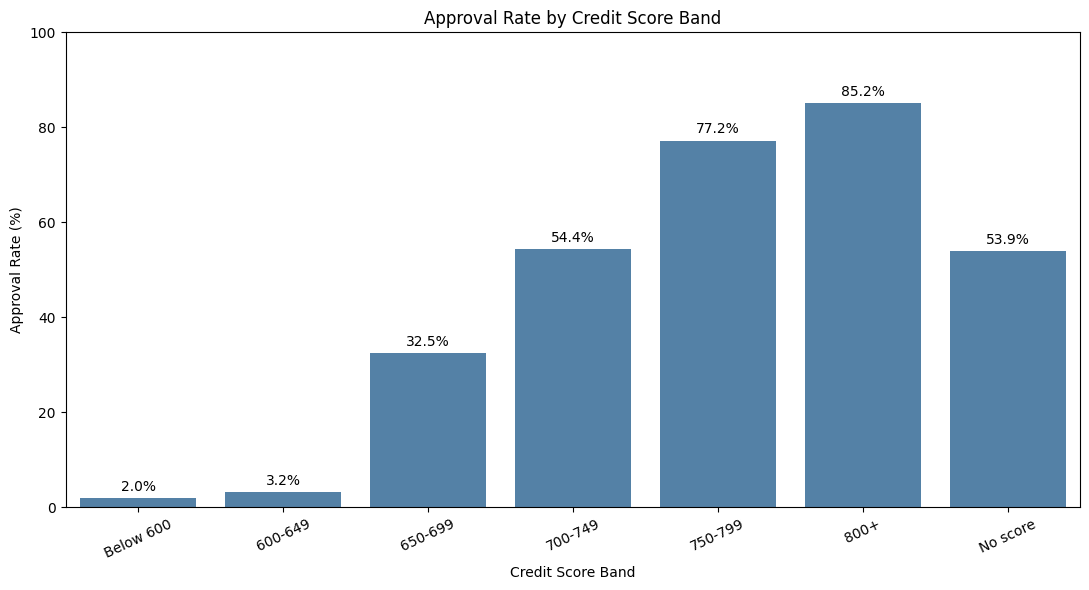

In [18]:
import seaborn as sns

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=score_approval.reset_index(),
    x="credit_score_band",
    y="approval_rate",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Approval Rate by Credit Score Band")
plt.xlabel("Credit Score Band")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

### Credit Score and Approval Analysis

Yes. Applicants scoring below 650 were almost never approved: 2.03% of those below 600 and 3.22% of those between 600 and 649. Approval jumps to 32.50% in the 650–699 band, so the historical data points to an unwritten minimum score of about 650. Applicants with no credit score were approved 53.90% of the time, slightly above the 52.85% for scored applicants, so a missing score was not treated as a reason to decline.


In [19]:
employment_approval = (
    df.groupby("employment_type")
      .agg(
          total_applications=("decision", "size"),
          approved_applications=(
              "decision",
              lambda x: (x == "Approved").sum()
          )
      )
)

employment_approval["approval_rate"] = (
    employment_approval["approved_applications"]
    / employment_approval["total_applications"] * 100
)

employment_approval = employment_approval.sort_values(
    "approval_rate", ascending=False
)

display(employment_approval.round())

,total_applications,approved_applications,approval_rate
employment_type,,,
Salaried,7057,4119,58.0
Business Owner,1749,895,51.0
Self-Employed Professional,1428,722,51.0
Gig / Contract,1766,617,35.0


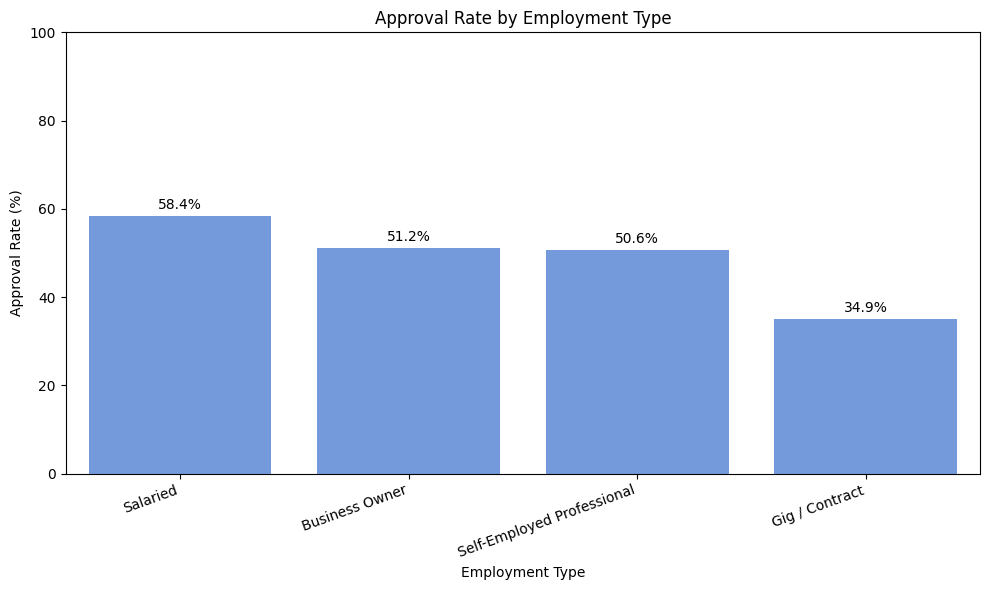

In [20]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=employment_approval.reset_index(),
    x="employment_type",
    y="approval_rate",
    color="cornflowerblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Approval Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


### Employment Type and Approval Analysis

I found that Salaried applicants had the highest approval rate at 58.37%, followed by Business Owners at 51.17% and Self-Employed Professionals at 50.56%. Gig / Contract workers had the lowest approval rate at 34.94%. This suggests that the bank's historical decisions were associated with employment type, potentially reflecting differences in income stability or repayment predictability. However, these results alone do not establish the reasons for the differences, so I will consider employment type alongside affordability and credit-history indicators in the following steps.


In [21]:
df["score_status"] = np.where(
    df["credit_score"].isna(),
    "No score",
    "Scored"
)

score_status_approval = (
    df.groupby("score_status")
      .agg(
          total_applications=("decision", "size"),
          approved_applications=(
              "decision",
              lambda x: (x == "Approved").sum()
          )
      )
)

score_status_approval["approval_rate"] = (
    score_status_approval["approved_applications"]
    / score_status_approval["total_applications"] * 100
)

display(score_status_approval.round(2))

,total_applications,approved_applications,approval_rate
score_status,,,
No score,1039,560,53.90
Scored,10961,5793,52.85


,applications,approved,approval_rate_pct
credit_score_band,,,
600-649,933,30,3.22
650-699,2529,822,32.50
700-749,3377,1836,54.37
750-799,2526,1950,77.20
800+,1350,1150,85.19
Below 600,246,5,2.03
No score,1039,560,53.90


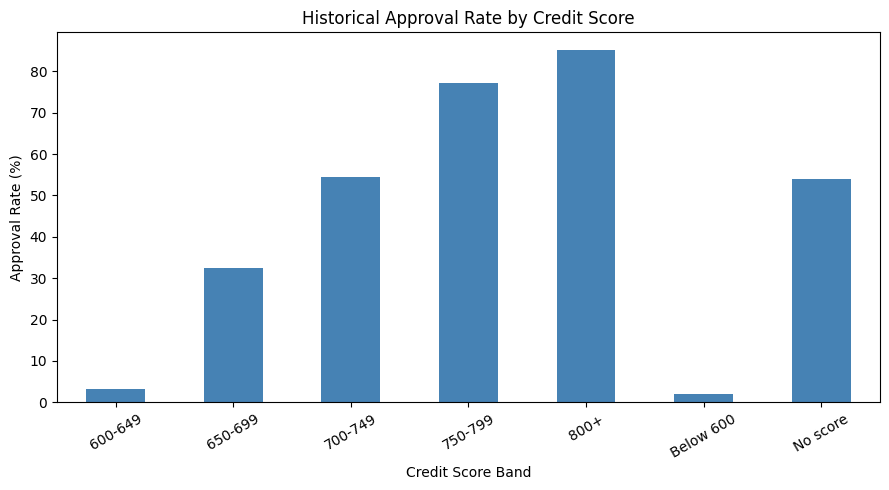

In [22]:
# Create credit-score bands
score_bins = [-np.inf, 599, 649, 699, 749, 799, np.inf]
score_labels = [
    "Below 600", "600-649", "650-699",
    "700-749", "750-799", "800+"
]

df["credit_score_band"] = pd.cut(
    df["credit_score"],
    bins=score_bins,
    labels=score_labels
).astype("object")

df["credit_score_band"] = (
    df["credit_score_band"].fillna("No score")
)

approval_by_score = df.groupby(
    "credit_score_band", observed=False
).agg(
    applications=("decision", "size"),
    approved=("decision", lambda x: (x == "Approved").sum())
)

approval_by_score["approval_rate_pct"] = (
    approval_by_score["approved"]
    / approval_by_score["applications"] * 100
)

display(approval_by_score.round(2))

approval_by_score["approval_rate_pct"].plot(
    kind="bar", figsize=(9, 5), color="steelblue"
)
plt.title("Historical Approval Rate by Credit Score")
plt.xlabel("Credit Score Band")
plt.ylabel("Approval Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,applications,approved,approval_rate_pct
employment_type,,,
Business Owner,1749,895,51.17
Gig / Contract,1766,617,34.94
Salaried,7057,4119,58.37
Self-Employed Professional,1428,722,50.56


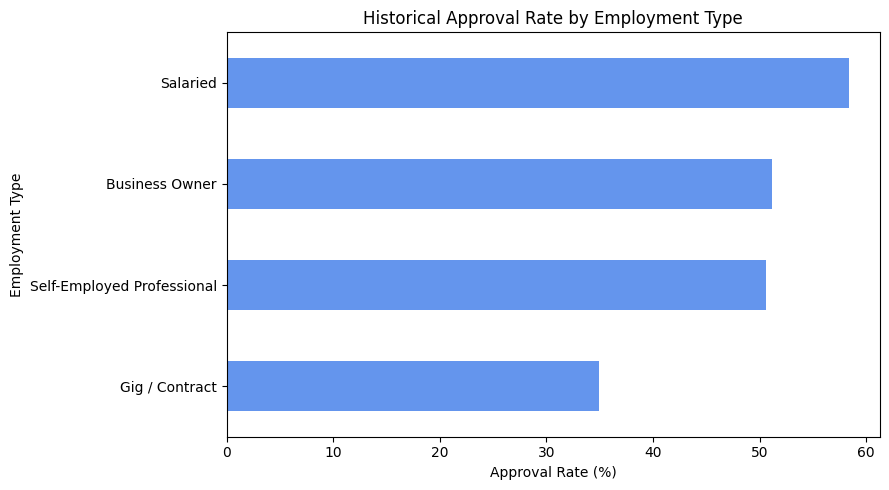

In [23]:
approval_by_employment = df.groupby("employment_type").agg(
    applications=("decision", "size"),
    approved=("decision", lambda x: (x == "Approved").sum())
)

approval_by_employment["approval_rate_pct"] = (
    approval_by_employment["approved"]
    / approval_by_employment["applications"] * 100
)

display(approval_by_employment.round(2))

approval_by_employment["approval_rate_pct"].sort_values().plot(
    kind="barh", figsize=(9, 5), color="cornflowerblue"
)
plt.title("Historical Approval Rate by Employment Type")
plt.xlabel("Approval Rate (%)")
plt.ylabel("Employment Type")
plt.tight_layout()
plt.show()


### Overall Findings: What Drives Approval Today?

My analysis shows that credit score is strongly associated with historical loan approval. Applications scoring below 600 had an approval rate of just 2.03%, and those scoring between 600 and 649 had an approval rate of 3.22%. This suggests a strong historical preference against approving applicants with scores below 650, although it does not establish a formal minimum-score policy.

Applicants without a credit score had an approval rate of 53.90%, compared with 52.85% for applicants with a recorded score. Therefore, missing credit scores did not automatically correspond to lower approval rates in this dataset. Employment type was also associated with approval outcomes: Salaried applicants had the highest approval rate at 58.37%, while Gig / Contract workers had the lowest at 34.94%.

These findings suggest that credit score and employment type are useful variables to investigate when developing the pre-screening model. However, historical approval patterns should not automatically be treated as ideal credit policy. The bank should also evaluate affordability, repayment risk and fairness before automating any decisions.



# 5.3 Engineer the Affordability Features

In this step, I created three new features to evaluate applicants' repayment affordability and credit-history status. I calculated the Fixed Obligation to Income Ratio (FOIR), the loan-to-income ratio, and a new-to-credit indicator. I then grouped applicants into FOIR bands and compared their historical loan approval rates to understand how repayment obligations relate to credit decisions.


,applications,approved,approval_rate_pct
foir_band,,,
Below 30%,5290,3477,65.73
30-40%,2422,1435,59.25
40-50%,1713,823,48.04
50-55%,519,168,32.37
Above 55%,1615,229,14.18


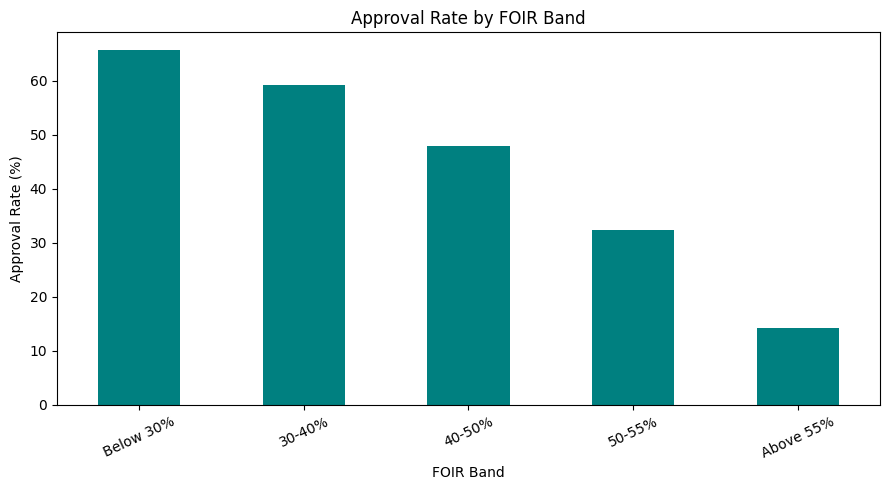

In [24]:
# Avoid division by zero
income = df["monthly_income"].replace(0, np.nan)

# Create the required features
df["foir"] = (
    (df["existing_emi"] + df["proposed_emi"]) / income
)

df["loan_to_income"] = (
    df["loan_amount"] / (income * 12)
)

df["is_ntc"] = df["credit_score"].isna().astype(int)

# Create FOIR bands
foir_bins = [-np.inf, 0.30, 0.40, 0.50, 0.55, np.inf]
foir_labels = [
    "Below 30%", "30-40%", "40-50%",
    "50-55%", "Above 55%"
]

df["foir_band"] = pd.cut(
    df["foir"],
    bins=foir_bins,
    labels=foir_labels,
    right=False
)

foir_analysis = df.groupby("foir_band", observed=False).agg(
    applications=("decision", "size"),
    approved=("decision", lambda x: (x == "Approved").sum())
)

foir_analysis["approval_rate_pct"] = (
    foir_analysis["approved"]
    / foir_analysis["applications"] * 100
)

display(foir_analysis.round(2))

foir_analysis["approval_rate_pct"].plot(
    kind="bar", figsize=(9, 5), color="teal"
)
plt.title("Approval Rate by FOIR Band")
plt.xlabel("FOIR Band")
plt.ylabel("Approval Rate (%)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [25]:
# Display the newly engineered features
display(
    df[
        [
            "monthly_income",
            "existing_emi",
            "proposed_emi",
            "foir",
            "loan_amount",
            "loan_to_income",
            "credit_score",
            "is_ntc"
        ]
    ].head(10)
)

,monthly_income,existing_emi,proposed_emi,foir,loan_amount,loan_to_income,credit_score,is_ntc
0,95000.0,23500.0,6600.0,0.316842,240000.0,0.210526,784.0,0
1,43000.0,8500.0,5000.0,0.313953,145000.0,0.281008,790.0,0
2,35000.0,3500.0,11800.0,0.437143,345000.0,0.821429,718.0,0
3,44500.0,0.0,4600.0,0.103371,135000.0,0.252809,NaN,1
4,83500.0,6000.0,33600.0,0.474251,700000.0,0.698603,700.0,0
5,105000.0,6000.0,12100.0,0.172381,355000.0,0.281746,808.0,0
6,30000.0,2000.0,14800.0,0.560000,165000.0,0.458333,792.0,0
7,NaN,16500.0,37700.0,NaN,785000.0,NaN,634.0,0
8,74500.0,19000.0,21800.0,0.547651,455000.0,0.508949,738.0,0
9,NaN,5500.0,26700.0,NaN,780000.0,NaN,687.0,0


In [26]:
print("FOIR Summary:")
display(df["foir"].describe())

print("\nLoan-to-Income Summary:")
display(df["loan_to_income"].describe())

print("\nNew-to-Credit Distribution:")
print(df["is_ntc"].value_counts())

print("\nMissing values in engineered features:")
print(df[["foir", "loan_to_income", "is_ntc"]].isnull().sum())

FOIR Summary:


count    11559.000000
mean         0.355792
std          0.198464
min          0.004798
25%          0.215162
50%          0.316230
75%          0.448795
max          1.505164
Name: foir, dtype: float64


Loan-to-Income Summary:


count    11559.000000
mean         0.527391
std          0.212983
min          0.014731
25%          0.347222
50%          0.519126
75%          0.698043
max          1.084656
Name: loan_to_income, dtype: float64


New-to-Credit Distribution:
is_ntc
0    10961
1     1039
Name: count, dtype: int64

Missing values in engineered features:
foir              441
loan_to_income    441
is_ntc              0
dtype: int64


In [27]:
foir_bins = [-np.inf, 0.30, 0.40, 0.50, 0.55, np.inf]

foir_labels = [
    "Below 30%",
    "30-40%",
    "40-50%",
    "50-55%",
    "Above 55%"
]

df["foir_band"] = pd.cut(
    df["foir"],
    bins=foir_bins,
    labels=foir_labels,
    right=False
)

print("Applications by FOIR band:")
print(df["foir_band"].value_counts(sort=False))

Applications by FOIR band:
foir_band
Below 30%    5290
30-40%       2422
40-50%       1713
50-55%        519
Above 55%    1615
Name: count, dtype: int64


In [28]:
foir_order = [
    "Below 30%",
    "30-40%",
    "40-50%",
    "50-55%",
    "Above 55%"
]

foir_approval = (
    df.groupby("foir_band", observed=False)
      .agg(
          total_applications=("decision", "size"),
          approved_applications=(
              "decision",
              lambda x: (x == "Approved").sum()
          )
      )
      .reindex(foir_order)
)

foir_approval["approval_rate"] = (
    foir_approval["approved_applications"]
    / foir_approval["total_applications"] * 100
)

display(foir_approval.round(2))

,total_applications,approved_applications,approval_rate
foir_band,,,
Below 30%,5290,3477,65.73
30-40%,2422,1435,59.25
40-50%,1713,823,48.04
50-55%,519,168,32.37
Above 55%,1615,229,14.18


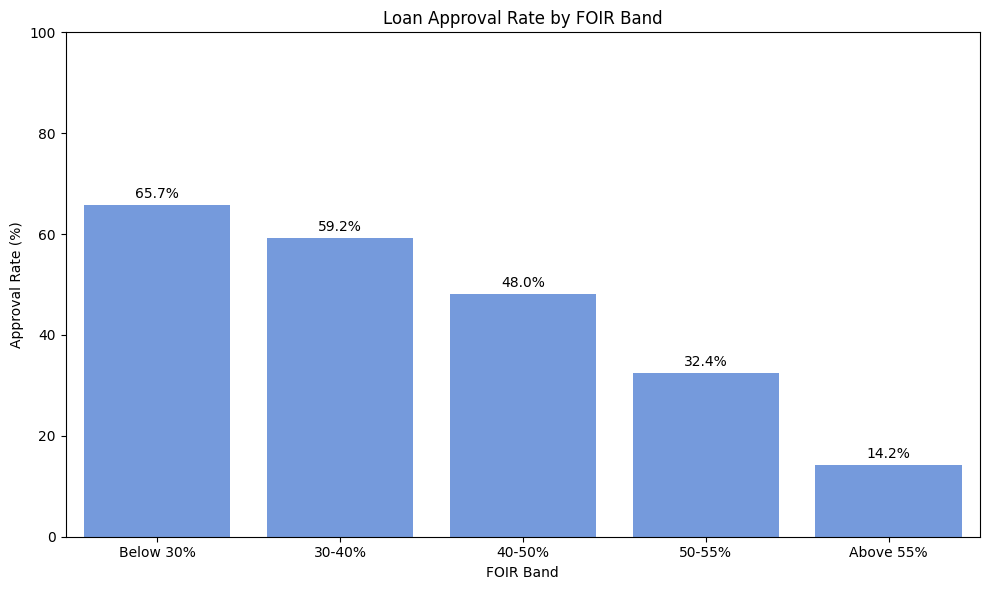

In [29]:
plot_data = foir_approval.reset_index()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=plot_data,
    x="foir_band",
    y="approval_rate",
    color="cornflowerblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Loan Approval Rate by FOIR Band")
plt.xlabel("FOIR Band")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### FOIR Analysis and Credit Policy Recommendation

Approval falls sharply once FOIR passes 50%. Applications below 30% were approved 65.73% of the time, 30–40% were approved 59.25%, and 40–50% were approved 48.04%. Approval then drops to 32.37% in the 50–55% band and 14.18% above 55%.

If I were writing this into a credit policy, I would propose a preliminary FOIR limit of 50%. Applications above 50% would go to an analyst for an affordability check rather than being approved automatically, and applications above 55% would need the strongest justification before approval.


In [30]:
# Check engineered features for invalid values
engineered_features = ["foir", "loan_to_income"]

print("Infinite values:")
print(np.isinf(df[engineered_features]).sum())

print("\nMissing values:")
print(df[engineered_features].isna().sum())

print("\nLargest feature values:")
display(df[engineered_features].describe())

Infinite values:
foir              0
loan_to_income    0
dtype: int64

Missing values:
foir              441
loan_to_income    441
dtype: int64

Largest feature values:


,foir,loan_to_income
count,11559.000000,11559.000000
mean,0.355792,0.527391
std,0.198464,0.212983
min,0.004798,0.014731
25%,0.215162,0.347222
50%,0.316230,0.519126
75%,0.448795,0.698043
max,1.505164,1.084656



## 5.4 Build the Logistic Regression Pre-Screener

In this step, I built a Logistic Regression classification model to predict loan declines based on historical application data. I defined Declined as class 1 and Approved as class 0. I selected the specified financial, demographic, credit-history and loan-related features while excluding identifiers, application dates, city, gender and the original decision column from the predictors. I then prepared the numeric and categorical features for model training.


In [31]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    classification_report
)

In [32]:
# Target: 1 = Declined, 0 = Approved
y = (df["decision"] == "Declined").astype(int)

# Select only the 12 required features
numeric_features = [
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months",
    "city_tier"
]

categorical_features = [
    "employment_type",
    "loan_purpose"
]

feature_columns = numeric_features + categorical_features

X = df[feature_columns].copy()

print("Feature shape:", X.shape)
print("Target distribution:")
print(y.value_counts().rename(index={0: "Approved", 1: "Declined"}))

Feature shape: (12000, 12)
Target distribution:
decision
Approved    6353
Declined    5647
Name: count, dtype: int64


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training records: 9600
Testing records: 2400

Training target distribution:
decision
0    0.529
1    0.471
Name: proportion, dtype: float64

Testing target distribution:
decision
0    0.53
1    0.47
Name: proportion, dtype: float64


In [34]:
# Numeric preprocessing:
# Fill missing values with the median, then scale
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing:
# Fill any missing categories and one-hot encode them
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each feature group
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [35]:
# Check for infinite values before train-test split
print("Infinite values in numeric features:")
print(np.isinf(X[numeric_features]).sum())

print("\nMissing values in numeric features:")
print(X[numeric_features].isnull().sum())

Infinite values in numeric features:
credit_score            0
is_ntc                  0
foir                    0
loan_to_income          0
delinquencies_24m       0
num_active_loans        0
years_in_current_job    0
age                     0
tenure_months           0
city_tier               0
dtype: int64

Missing values in numeric features:
credit_score            1039
is_ntc                     0
foir                     441
loan_to_income           441
delinquencies_24m          0
num_active_loans           0
years_in_current_job       0
age                        0
tenure_months              0
city_tier                  0
dtype: int64


In [36]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000,solver='liblinear', class_weight='balanced'))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Predict the test-set outcomes
y_pred = logistic_model.predict(X_test)

print("Model training completed.")

Model training completed.


/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [37]:
accuracy = accuracy_score(y_test, y_pred)

declined_precision = precision_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

declined_recall = recall_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

print(f"Accuracy: {accuracy:.4f}")
print(f"Declined-class precision: {declined_precision:.4f}")
print(f"Declined-class recall: {declined_recall:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Approved", "Declined"],
    zero_division=0
))

Accuracy: 0.7854
Declined-class precision: 0.7688
Declined-class recall: 0.7777

Classification report:
              precision    recall  f1-score   support

    Approved       0.80      0.79      0.80      1271
    Declined       0.77      0.78      0.77      1129

    accuracy                           0.79      2400
   macro avg       0.78      0.78      0.78      2400
weighted avg       0.79      0.79      0.79      2400



In [38]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix")
print("Rows = Actual | Columns = Predicted")
print("Order: Approved (0), Declined (1)")
print(cm)

print("\nTrue Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)

Confusion Matrix
Rows = Actual | Columns = Predicted
Order: Approved (0), Declined (1)
[[1007  264]
 [ 251  878]]

True Negatives (TN): 1007
False Positives (FP): 264
False Negatives (FN): 251
True Positives (TP): 878


In [39]:
# Retrieve feature names after preprocessing
feature_names = logistic_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Extract trained Logistic Regression coefficients
coefficients = logistic_model.named_steps[
    "classifier"
].coef_[0]

coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

coefficient_table["absolute_coefficient"] = (
    coefficient_table["coefficient"].abs()
)

top_five_coefficients = (
    coefficient_table
    .sort_values("absolute_coefficient", ascending=False)
    .head(5)
)

display(top_five_coefficients.round(4))

,feature,coefficient,absolute_coefficient
2,numeric__foir,1.0974,1.0974
0,numeric__credit_score,-0.9994,0.9994
4,numeric__delinquencies_24m,0.9911,0.9911
11,categorical__employment_type_Gig / Contract,0.6155,0.6155
12,categorical__employment_type_Salaried,-0.4513,0.4513


### Logistic Regression Model Evaluation

On the 2,400-application test set, the Logistic Regression model is correct 78.5% of the time. It identifies 77.8% of the applications that were actually declined (recall), and 76.9% of the applications it declines are genuinely declined (precision).

In business terms, the key figure is the false positives. The model wrongly declined 264 of the 1,271 test applications that the credit team approved, which is 20.8% of creditworthy applicants. Those are customers the model would have turned away. It also let 251 of the 1,129 declined applications (22.2%) through as predicted approvals, which is a risk rather than a customer-harm issue. A model that wrongly declines one in five good applicants is not safe to use without human review.


### Interpretation of the Top Five Coefficients

The five largest coefficients, on standardised inputs, are FOIR (+1.10), credit score (−1.00), delinquencies in the last 24 months (+0.99), Gig / Contract employment (+0.62) and Salaried employment (−0.45). A positive coefficient pushes an application towards Declined, and a negative coefficient pushes it towards Approved.

For a credit analyst, the story is straightforward. A high repayment burden and recent delinquencies are the strongest drivers of decline, a higher credit score is the strongest protection against decline, Gig / Contract employment pushes towards decline, and Salaried employment pushes towards approval. FOIR and credit score match the patterns found in Steps 5.2 and 5.3.


In [40]:
# False-decline rate among historically approved applicants (classification metric)
wrongly_declined = fp
actual_approved = tn + fp

false_decline_rate_among_approved = (
    fp / actual_approved * 100
    if actual_approved > 0 else 0
)

print("Historically approved applicants in test set:", actual_approved)
print("Historically approved applicants predicted as Declined:", wrongly_declined)
print(
    "False-decline rate among historically approved applicants: "
    f"{false_decline_rate_among_approved:.2f}%"
)
print(
    "Note: this denominator differs from the policy risk in Step 5.5, "
    "which is wrongly declined applicants divided by all auto-declined applicants."
)

Historically approved applicants in test set: 1271
Historically approved applicants predicted as Declined: 264
False-decline rate among historically approved applicants: 20.77%
Note: this denominator differs from the policy risk in Step 5.5, which is wrongly declined applicants divided by all auto-declined applicants.



### Step 5.4 Conclusion

I developed a Logistic Regression baseline to predict loan declines using the specified applicant and loan features. I used median imputation and scaling for numeric variables, one-hot encoding for categorical variables, and an 80/20 stratified train-test split with random_state=42. I evaluated the model using accuracy, precision, recall and the confusion matrix, and examined the five largest coefficients to understand the main factors associated with decline predictions. The false-positive count represents applications approved by the historical credit team that the model incorrectly predicts as declined. I will use this baseline to investigate a more conservative auto-decline threshold in Step 5.5, where the bank's requirement is that no more than 5% of automatically declined applications should have been historically approved.



## 5.5 Set the Auto-Decline Threshold

In this step, I used the trained Logistic Regression model to calculate the probability of decline for each application in the test dataset. I evaluated different probability thresholds to understand the trade-off between reducing manual reviews and wrongly declining applications that the historical credit team approved. My objective was to select the threshold that satisfies the bank's maximum 5% wrong-decline limit while automating as many applications as possible.


In [41]:
# Probability of class 1, which represents Declined
decline_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Combine actual outcomes and predicted probabilities
threshold_df = pd.DataFrame({
    "actual_decision": y_test.to_numpy(),
    "decline_probability": decline_probabilities
})

print("Number of test applications:", len(threshold_df))
display(threshold_df.head())

Number of test applications: 2400


/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,actual_decision,decline_probability
0,0,0.157173
1,1,0.835770
2,0,0.584927
3,1,0.834533
4,0,0.173052


In [42]:
thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]

results = []

for threshold in thresholds:

    # Auto-decline applications with sufficiently high decline probability
    auto_decline = (
        threshold_df["decline_probability"] >= threshold
    )

    selected = threshold_df.loc[auto_decline]

    total_auto_declined = len(selected)

    # Historically approved applications incorrectly auto-declined
    wrongly_declined = (
        selected["actual_decision"] == 0
    ).sum()

    # Percentage of all test applications auto-declined
    auto_decline_pct = (
        total_auto_declined / len(threshold_df) * 100
    )

    # Percentage of auto-declined applications that were historically approved
    wrong_decline_pct = (
        wrongly_declined / total_auto_declined * 100
        if total_auto_declined > 0
        else np.nan
    )

    results.append({
        "threshold": threshold,
        "auto_declined_count": total_auto_declined,
        "auto_decline_pct": auto_decline_pct,
        "wrongly_declined_count": wrongly_declined,
        "wrongly_declined_pct": wrong_decline_pct
    })

threshold_results = pd.DataFrame(results)

display(threshold_results.round(2))

,threshold,auto_declined_count,auto_decline_pct,wrongly_declined_count,wrongly_declined_pct
0,0.50,1142,47.58,264,23.12
1,0.60,974,40.58,180,18.48
2,0.70,784,32.67,105,13.39
3,0.80,603,25.12,50,8.29
4,0.85,501,20.88,30,5.99
5,0.90,395,16.46,21,5.32
6,0.95,255,10.62,7,2.75


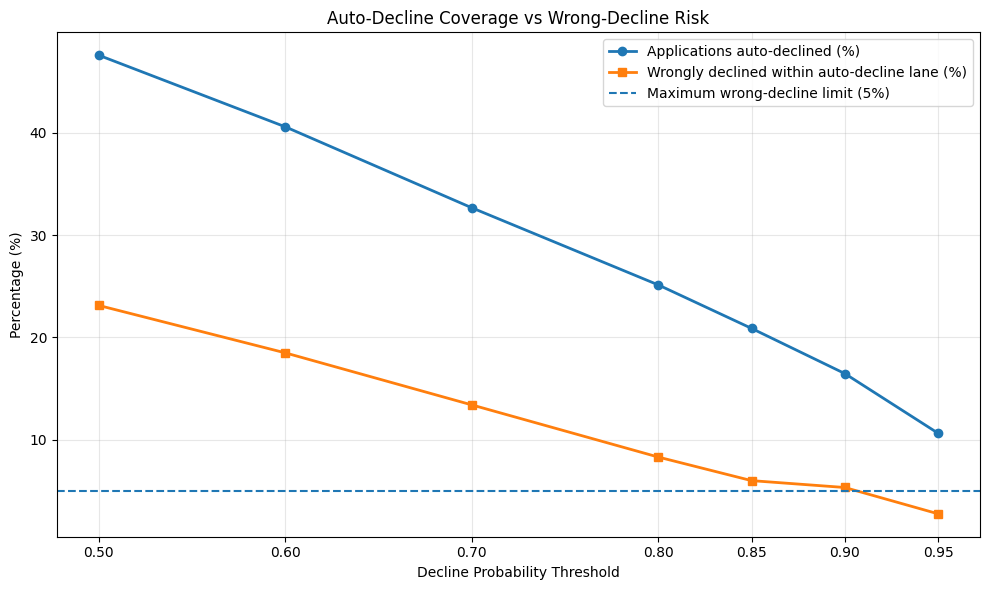

In [43]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results["threshold"],
    threshold_results["auto_decline_pct"],
    marker="o",
    linewidth=2,
    label="Applications auto-declined (%)"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["wrongly_declined_pct"],
    marker="s",
    linewidth=2,
    label="Wrongly declined within auto-decline lane (%)"
)

plt.axhline(
    y=5,
    linestyle="--",
    label="Maximum wrong-decline limit (5%)"
)

plt.title("Auto-Decline Coverage vs Wrong-Decline Risk")
plt.xlabel("Decline Probability Threshold")
plt.ylabel("Percentage (%)")
plt.xticks(thresholds)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [44]:
# Keep only thresholds that satisfy the bank's risk limit
eligible_thresholds = threshold_results[
    (threshold_results["wrongly_declined_pct"] <= 5)
    & (threshold_results["auto_declined_count"] > 0)
]

if eligible_thresholds.empty:
    recommended_threshold = None
    recommended_row = None

    print(
        "No tested threshold satisfies the 5% wrong-decline limit. "
        "Further model improvement or validation is required."
    )

else:
    # Select the eligible threshold with the highest coverage
    recommended_row = eligible_thresholds.sort_values(
        ["auto_decline_pct", "threshold"],
        ascending=[False, False]
    ).iloc[0]

    recommended_threshold = float(recommended_row["threshold"])

    print(f"Recommended threshold: {recommended_threshold:.2f}")
    print(f"Auto-decline coverage: {recommended_row['auto_decline_pct']:.2f}%")
    print(f"Wrong-decline rate: {recommended_row['wrongly_declined_pct']:.2f}%")
    print(f"Test applications auto-declined: {int(recommended_row['auto_declined_count'])}")



Recommended threshold: 0.95
Auto-decline coverage: 10.62%
Wrong-decline rate: 2.75%
Test applications auto-declined: 255


In [45]:
if recommended_threshold is not None:

    monthly_applications = 3000
    review_minutes = 25

    monthly_auto_declined = round(
        monthly_applications
        * recommended_row["auto_decline_pct"] / 100
    )

    monthly_hours_freed = (
        monthly_auto_declined * review_minutes / 60
    )

    print("RECOMMENDED AUTO-DECLINE BUSINESS CASE")
    print("--------------------------------------")
    print(f"Recommended threshold: {recommended_threshold:.2f}")
    print(f"Auto-decline coverage: "
          f"{recommended_row['auto_decline_pct']:.2f}%")
    print(f"Wrong-decline rate: "
          f"{recommended_row['wrongly_declined_pct']:.2f}%")
    print(f"Estimated applications auto-declined monthly: "
          f"{monthly_auto_declined}")
    print(f"Estimated analyst hours freed monthly: "
          f"{monthly_hours_freed:.2f}")

else:
    print(
        "No monthly auto-decline recommendation can be made "
        "under the current 5% risk constraint."
    )

RECOMMENDED AUTO-DECLINE BUSINESS CASE
--------------------------------------
Recommended threshold: 0.95
Auto-decline coverage: 10.62%
Wrong-decline rate: 2.75%
Estimated applications auto-declined monthly: 319
Estimated analyst hours freed monthly: 132.92



### Step 5.5 Conclusion: Auto-Decline Threshold

I evaluated decline probability thresholds of 0.50, 0.60, 0.70, 0.80, 0.85, 0.90 and 0.95 using the held-out test dataset. For each threshold, I measured auto-decline coverage and the percentage of auto-declined applications that had historically been approved.

I selected a threshold of **0.95** because it satisfies the bank's requirement that the wrong-decline rate must not exceed 5%, while maximising coverage among the tested thresholds. At this threshold, **10.62%** of test applications qualified for auto-decline, and the observed wrong-decline rate was **2.75%**.

Extrapolating these results to 3,000 monthly applications gives approximately **319 applications auto-declined per month** and **132.92 analyst hours freed monthly**, assuming 25 minutes per manual review. These are estimates based on held-out test performance, not guaranteed operational outcomes. The bank should validate the model prospectively and retain appropriate human oversight before deploying automated decisions.

**Important limitation:** if the threshold was selected by searching over the test set, its performance estimate is exploratory and may be optimistic. Select thresholds on validation data and evaluate the fixed threshold once on an untouched test set.



## 5.6 Fairness Check

In this step, I evaluated whether historical loan approval decisions and the model's auto-decline predictions differed across gender groups. I compared historical approval rates overall and within employment types, median monthly income, and the share of Gig / Contract workers. Finally, I compared auto-decline rates at the threshold selected in Step 5.5 to identify potential disparities that may require further investigation.


In [46]:
gender_approval = (
    df.groupby("gender")
      .agg(
          total_applications=("decision", "size"),
          approved_applications=(
              "decision",
              lambda x: (x == "Approved").sum()
          )
      )
)

gender_approval["approval_rate"] = (
    gender_approval["approved_applications"]
    / gender_approval["total_applications"] * 100
)

display(gender_approval.round(2))

,total_applications,approved_applications,approval_rate
gender,,,
Female,3795,1914,50.43
Male,8205,4439,54.10


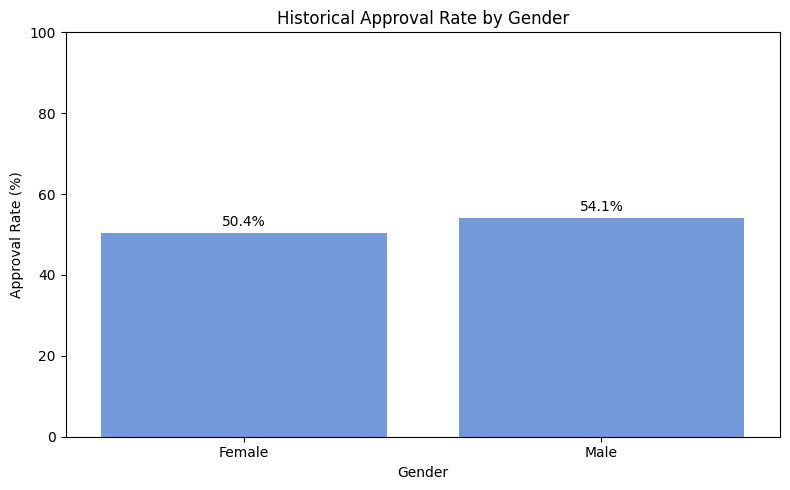

In [47]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=gender_approval.reset_index(),
    x="gender",
    y="approval_rate",
    color="cornflowerblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Historical Approval Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [48]:
gender_employment_approval = (
    df.groupby(["employment_type", "gender"])
      .agg(
          total_applications=("decision", "size"),
          approved_applications=(
              "decision",
              lambda x: (x == "Approved").sum()
          )
      )
      .reset_index()
)

gender_employment_approval["approval_rate"] = (
    gender_employment_approval["approved_applications"]
    / gender_employment_approval["total_applications"] * 100
)

display(gender_employment_approval.round(2))

,employment_type,gender,total_applications,approved_applications,approval_rate
0,Business Owner,Female,370,191,51.62
1,Business Owner,Male,1379,704,51.05
2,Gig / Contract,Female,811,281,34.65
3,Gig / Contract,Male,955,336,35.18
4,Salaried,Female,2150,1221,56.79
5,Salaried,Male,4907,2898,59.06
6,Self-Employed Professional,Female,464,221,47.63
7,Self-Employed Professional,Male,964,501,51.97


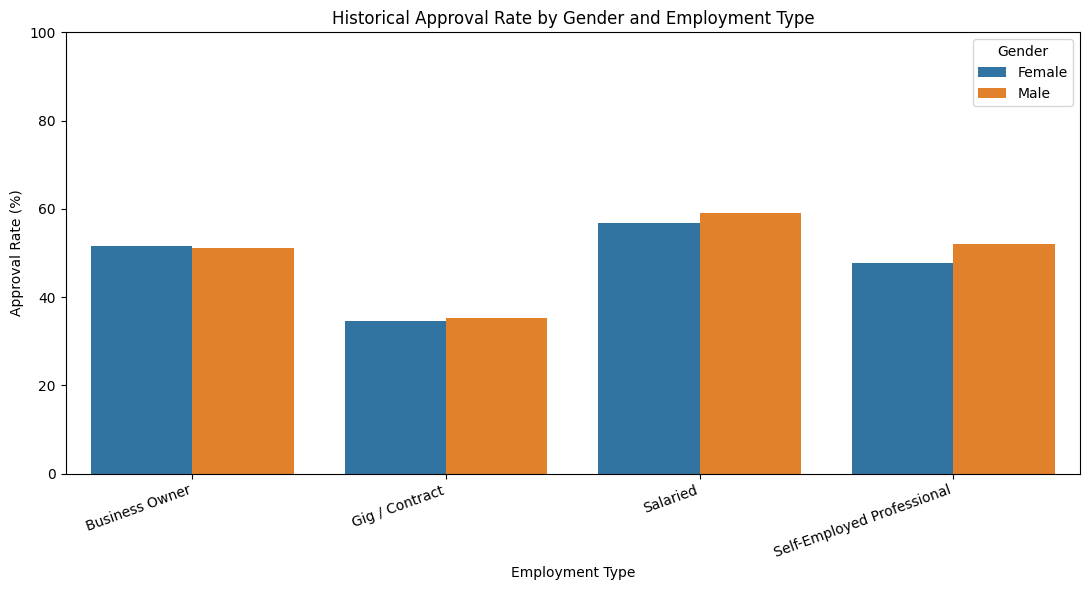

In [49]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=gender_employment_approval,
    x="employment_type",
    y="approval_rate",
    hue="gender"
)

plt.title("Historical Approval Rate by Gender and Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Approval Rate (%)")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 100)
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

In [50]:
gender_income = (
    df.groupby("gender")
      .agg(
          total_applications=("monthly_income", "size"),
          median_monthly_income=("monthly_income", "median")
      )
)

display(gender_income.round(2))

,total_applications,median_monthly_income
gender,,
Female,3795,44000.0
Male,8205,54000.0


In [51]:
gig_workers = df["employment_type"].eq("Gig / Contract")

gender_gig_share = (
    df.assign(is_gig=gig_workers)
      .groupby("gender")
      .agg(
          total_applications=("is_gig", "size"),
          gig_contract_workers=("is_gig", "sum")
      )
)

gender_gig_share["gig_contract_share_pct"] = (
    gender_gig_share["gig_contract_workers"]
    / gender_gig_share["total_applications"] * 100
)

display(gender_gig_share.round(2))

,total_applications,gig_contract_workers,gig_contract_share_pct
gender,,,
Female,3795,811,21.37
Male,8205,955,11.64


In [52]:
if recommended_threshold is None:
    print("No threshold satisfied the 5% risk rule .")
else:
    # Predicted decline probabilities from the same test set
    auto_decline_predictions = (
        decline_probabilities >= recommended_threshold
    )

    # Preserve the test-set row alignment for gender comparison
    fairness_test = pd.DataFrame({
        "gender": df.loc[X_test.index, "gender"].to_numpy(),
        "auto_declined": auto_decline_predictions
    })

    gender_auto_decline = (
        fairness_test.groupby("gender")
        .agg(
            total_test_applications=("auto_declined", "size"),
            auto_declined_count=("auto_declined", "sum")
        )
    )

    gender_auto_decline["auto_decline_rate_pct"] = (
        gender_auto_decline["auto_declined_count"]
        / gender_auto_decline["total_test_applications"] * 100
    )

    display(gender_auto_decline.round(2))

,total_test_applications,auto_declined_count,auto_decline_rate_pct
gender,,,
Female,750,89,11.87
Male,1650,166,10.06


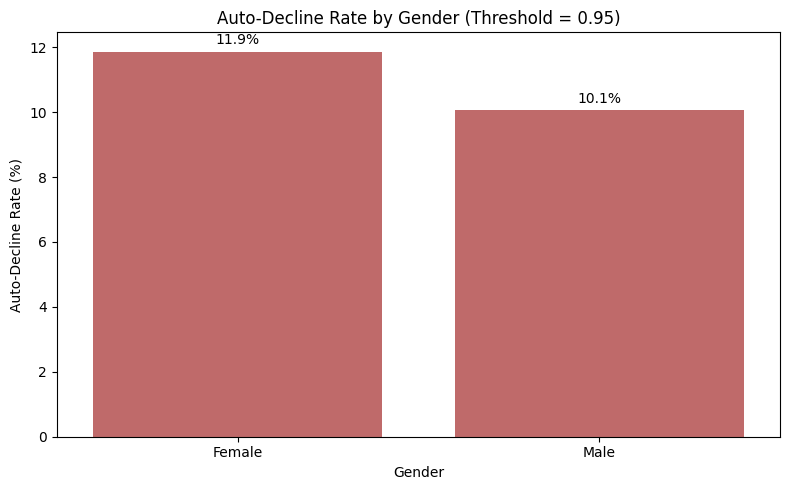

In [53]:
if recommended_threshold is not None:
    plt.figure(figsize=(8, 5))

    ax = sns.barplot(
        data=gender_auto_decline.reset_index(),
        x="gender",
        y="auto_decline_rate_pct",
        color="indianred"
    )

    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3)

    plt.title(
        f"Auto-Decline Rate by Gender "
        f"(Threshold = {recommended_threshold:.2f})"
    )
    plt.xlabel("Gender")
    plt.ylabel("Auto-Decline Rate (%)")
    plt.tight_layout()
    plt.show()

### Fairness Check Findings

There is a gap in the historical data: female applicants were approved 50.43% of the time, against 54.10% for male applicants. The gap persists within Salaried (56.79% against 59.06%) and Self-Employed Professionals (47.63% against 51.97%), while Business Owners and Gig / Contract workers show almost no gap. Part of the overall difference reflects composition, since female applicants have a lower median monthly income (₹44,000 against ₹54,000) and a higher share of Gig / Contract workers (21.37% against 11.64%), though these factors do not establish the cause. At the 0.95 threshold the model auto-declines 11.87% of female and 10.06% of male test applications, so it carries the same direction of disparity forward and does not narrow the gap; this comparison is not like-for-like with the approval gap, but it does not suggest the model removes the disparity. Gender should not be used as a model feature, and leaving it out does not solve the problem, because income, employment type and credit features can act as proxies for gender.


## 5.7 Interim Briefing

For the Logistic Regression model, I recommend an auto-decline threshold of 0.95 on the decline probability, which auto-declines 10.62% of test applications with a 2.75% wrong-decline rate. At 3,000 applications a month and 25 minutes per review, this frees about 319 manual reviews and roughly 133 analyst hours per month. The weakness I most want Part 2 to address is that this threshold was chosen on the test set, so its 2.75% wrong-decline rate is likely optimistic and must be checked on separate data.


# Part 2 — Model Comparison & Two-Lane Design

## 5.8 Rebuild the Baseline as a Pipeline

In this step, I rebuild the Logistic Regression baseline from the beginning using a single scikit-learn Pipeline. I will load the original dataset, prepare the features and target, create the same train-test split used in Step 5.4, and combine preprocessing with model training. Finally, I will compare the pipeline's performance with the original baseline and predict decline probabilities for the five most recent applications.

In [54]:
# Rebuild the Step 5.4 model as ONE pipeline that accepts raw application rows.
# The Step 5.3 features (foir, loan_to_income, is_ntc) are created inside the pipeline,
# so the same transformations run on training data and on any future application.

numeric_features = [
    "credit_score", "is_ntc", "foir", "loan_to_income", "delinquencies_24m",
    "num_active_loans", "years_in_current_job", "age", "tenure_months", "city_tier"
]
categorical_features = ["employment_type", "loan_purpose"]
feature_columns = numeric_features + categorical_features

def add_affordability_features(frame):
    """Build the model features from raw CSV columns (same logic as Step 5.3)."""
    out = frame.copy()
    income = out["monthly_income"].replace(0, np.nan)
    out["foir"] = (out["existing_emi"] + out["proposed_emi"]) / income
    out["loan_to_income"] = out["loan_amount"] / (income * 12)
    out["is_ntc"] = out["credit_score"].isna().astype(int)
    return out[feature_columns]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

pipeline_model = Pipeline([
    ("features", FunctionTransformer(add_affordability_features)),
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000, solver="liblinear", class_weight="balanced"))
])

# Raw rows for the same training / test indices used in Step 5.4
raw_df = pd.read_csv("MUC02_Credit_PreScreening_Dataset.csv")
X_train_raw = raw_df.loc[X_train.index]
X_test_raw = raw_df.loc[X_test.index]

pipeline_model.fit(X_train_raw, y_train)
pipeline_pred = pipeline_model.predict(X_test_raw)

pipeline_accuracy = accuracy_score(y_test, pipeline_pred)
pipeline_precision = precision_score(y_test, pipeline_pred, pos_label=1, zero_division=0)
pipeline_recall = recall_score(y_test, pipeline_pred, pos_label=1, zero_division=0)
pipeline_cm = confusion_matrix(y_test, pipeline_pred, labels=[0, 1])

print("PIPELINE MODEL RESULTS")
print(f"Accuracy: {pipeline_accuracy:.4f}")
print(f"Declined-class precision: {pipeline_precision:.4f}")
print(f"Declined-class recall: {pipeline_recall:.4f}")
print("\nConfusion matrix (Approved=0, Declined=1):")
print(pipeline_cm)

# Compare against the Step 5.4 model
baseline_pred = logistic_model.predict(X_test)
comparison = pd.DataFrame({
    "Step 5.4 Baseline": {
        "Accuracy": accuracy_score(y_test, baseline_pred),
        "Declined precision": precision_score(y_test, baseline_pred, pos_label=1, zero_division=0),
        "Declined recall": recall_score(y_test, baseline_pred, pos_label=1, zero_division=0),
    },
    "Step 5.8 Pipeline": {
        "Accuracy": pipeline_accuracy,
        "Declined precision": pipeline_precision,
        "Declined recall": pipeline_recall,
    }
})
display(comparison.round(4))
print("Predictions identical:", np.array_equal(baseline_pred, pipeline_pred))

PIPELINE MODEL RESULTS
Accuracy: 0.7854
Declined-class precision: 0.7688
Declined-class recall: 0.7777

Confusion matrix (Approved=0, Declined=1):
[[1007  264]
 [ 251  878]]


/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = 

,Step 5.4 Baseline,Step 5.8 Pipeline
Accuracy,0.7854,0.7854
Declined precision,0.7688,0.7688
Declined recall,0.7777,0.7777


Predictions identical: True


In [55]:
# Five most recent applications, passed as RAW rows straight from the CSV (no manual feature building).
# The application date is used only to sort; the rows themselves are not modified.
sort_dates = pd.to_datetime(raw_df["application_date"], errors="coerce")
latest_idx = (
    raw_df.assign(_sort_date=sort_dates)
          .sort_values(["_sort_date", "application_id"], ascending=[False, False])
          .head(5)
          .index
)
latest_five = raw_df.loc[latest_idx]

decline_probabilities = pipeline_model.predict_proba(latest_five)[:, 1]

latest_predictions = pd.DataFrame({
    "application_id": latest_five["application_id"].to_numpy(),
    "application_date": latest_five["application_date"].to_numpy(),
    "decline_probability": decline_probabilities,
    "predicted_decision_at_0.50": np.where(decline_probabilities >= 0.50, "Declined", "Approved")
})

display(latest_predictions.round(4))

,application_id,application_date,decline_probability,predicted_decision_at_0.50
0,APP112000,2026-09-30,0.4234,Approved
1,APP111999,2026-09-30,0.2492,Approved
2,APP111998,2026-09-30,0.6119,Declined
3,APP111997,2026-09-30,0.8696,Declined
4,APP111996,2026-09-30,0.5520,Declined


### Pipeline Results and Recent Application Predictions

Packaging the feature calculations, imputation, scaling and encoding into one pipeline means that next month's raw applications go through exactly the transformations learned from the training data only, which prevents data leakage from the test set or future applications. The rebuilt pipeline reproduced the Step 5.4 results exactly (accuracy 78.54%, with identical predictions), so the bank can score new applications directly from the CSV without hand-built steps that could drift or be applied inconsistently.



## 5.9 Compare Models with Cross-Validation

In this step, I compared Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting using five-fold StratifiedKFold cross-validation on the training data only. I recorded the mean ROC-AUC, accuracy, precision, and recall for the Declined class to evaluate both overall discrimination and the ability to identify declined applications. After comparing the results, I selected one model for a single evaluation on the held-out test set and examined its eight most important features.
 

In [56]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.base import clone
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
import pandas as pd
import numpy as np

# Gradient Boosting requires dense encoded categorical features
try:
    dense_encoder = OneHotEncoder(
        handle_unknown="ignore", sparse_output=False
    )
except TypeError:
    dense_encoder = OneHotEncoder(
        handle_unknown="ignore", sparse=False
    )

dense_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", dense_encoder)
])

dense_preprocessor = ColumnTransformer([
    ("numeric", clone(numeric_pipeline), numeric_features),
    ("categorical", dense_categorical_pipeline, categorical_features)
])

# Define all four models using the same feature preprocessing
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=2000,
            solver="liblinear",
            class_weight="balanced"
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(
            max_depth=6,
            min_samples_leaf=30,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=10,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", dense_preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=2,
            random_state=42
        ))
    ])
}

# Stratified five-fold cross-validation on training data only
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall"
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False
    )

    cv_results.append({
        "Model": name,
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Precision (Declined)": scores["test_precision"].mean(),
        "Mean Recall (Declined)": scores["test_recall"].mean()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    "Mean ROC-AUC", ascending=False
).reset_index(drop=True)

display(cv_results_df.round(4))


/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = 

,Model,Mean ROC-AUC,Mean Accuracy,Mean Precision (Declined),Mean Recall (Declined)
0,Gradient Boosting,0.8872,0.7999,0.8144,0.7446
1,Random Forest,0.8839,0.7946,0.7842,0.7776
2,Logistic Regression,0.8674,0.7773,0.7674,0.7561
3,Decision Tree,0.8662,0.7870,0.8084,0.7182


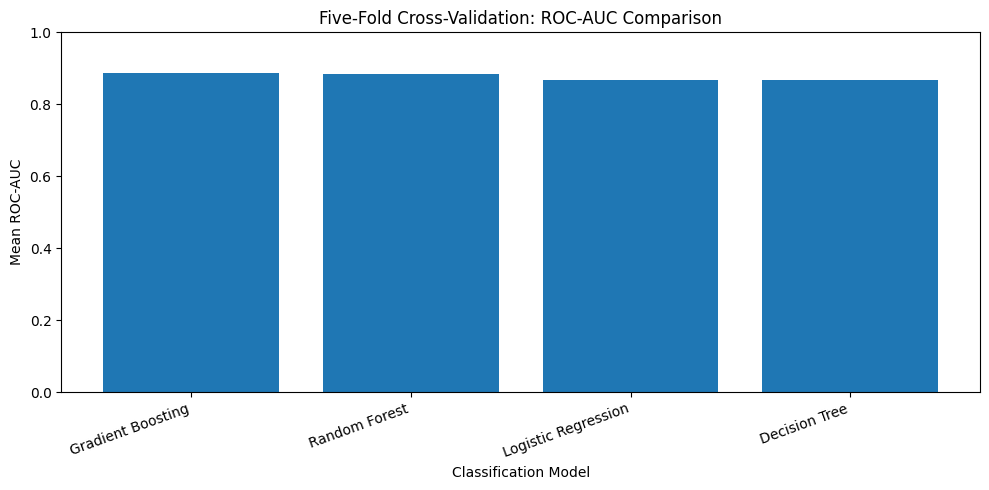

In [57]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    cv_results_df["Model"],
    cv_results_df["Mean ROC-AUC"]
)

plt.title("Five-Fold Cross-Validation: ROC-AUC Comparison")
plt.xlabel("Classification Model")
plt.ylabel("Mean ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


In [58]:

# Choose the model with the highest mean cross-validation ROC-AUC
best_model_name = cv_results_df.loc[0, "Model"]
best_model = models[best_model_name]

print("Selected model:", best_model_name)

# Fit on the complete training set, then evaluate once on the test set
best_model.fit(X_train, y_train)

test_probabilities = best_model.predict_proba(X_test)[:, 1]
test_predictions = best_model.predict(X_test)

print("\nHeld-out test results")
print(f"ROC-AUC: {roc_auc_score(y_test, test_probabilities):.4f}")
print(f"Accuracy: {accuracy_score(y_test, test_predictions):.4f}")
print(
    "Declined-class precision:",
    f"{precision_score(y_test, test_predictions, pos_label=1, zero_division=0):.4f}"
)
print(
    "Declined-class recall:",
    f"{recall_score(y_test, test_predictions, pos_label=1, zero_division=0):.4f}"
)

print("\nConfusion matrix (Approved=0, Declined=1):")
display(pd.DataFrame(
    confusion_matrix(y_test, test_predictions, labels=[0, 1]),
    index=["Actual Approved", "Actual Declined"],
    columns=["Predicted Approved", "Predicted Declined"]
))


Selected model: Gradient Boosting

Held-out test results
ROC-AUC: 0.8848
Accuracy: 0.7942
Declined-class precision: 0.8074
Declined-class recall: 0.7387

Confusion matrix (Approved=0, Declined=1):


,Predicted Approved,Predicted Declined
Actual Approved,1072,199
Actual Declined,295,834


,Feature,Importance
0,numeric__credit_score,0.3760
2,numeric__foir,0.2953
4,numeric__delinquencies_24m,0.2437
12,categorical__employment_type_Salaried,0.0201
6,numeric__years_in_current_job,0.0186
1,numeric__is_ntc,0.0173
11,categorical__employment_type_Gig / Contract,0.0142
5,numeric__num_active_loans,0.0098


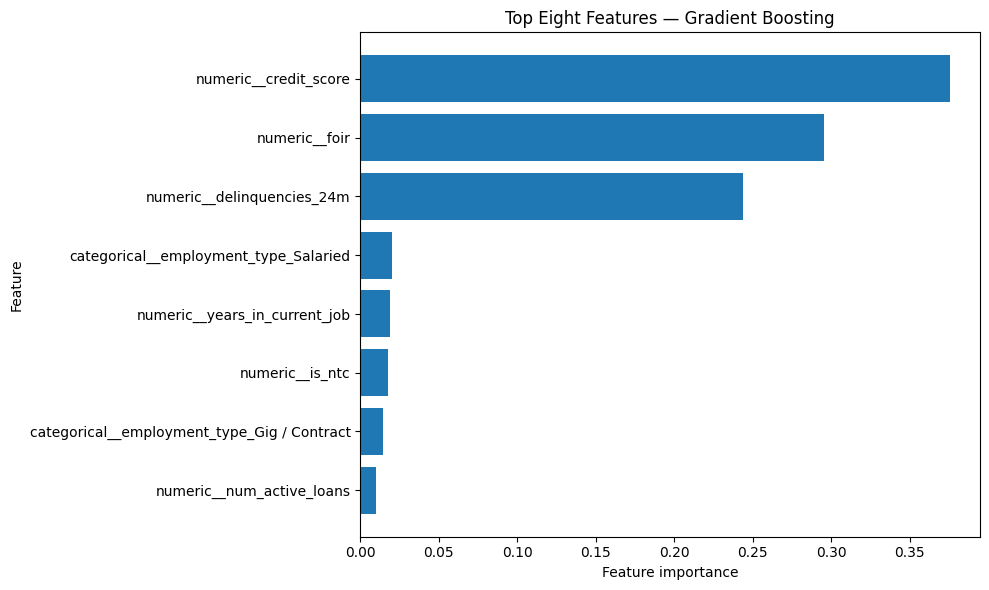

In [59]:

# Get feature names after preprocessing
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_classifier = best_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()

# Use model-specific importance scores
if hasattr(fitted_classifier, "feature_importances_"):
    importance_values = fitted_classifier.feature_importances_
    importance_label = "Feature importance"
else:
    importance_values = np.abs(fitted_classifier.coef_[0])
    importance_label = "Absolute coefficient magnitude"

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values("Importance", ascending=False)

top_eight = importance_df.head(8).sort_values(
    "Importance", ascending=True
)

display(top_eight.sort_values(
    "Importance", ascending=False
).round(4))

plt.figure(figsize=(10, 6))
plt.barh(top_eight["Feature"], top_eight["Importance"])
plt.title(f"Top Eight Features — {best_model_name}")
plt.xlabel(importance_label)
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


### Model Selection and Business Justification

I selected Gradient Boosting because it had the highest mean five-fold ROC-AUC (0.8872, against 0.8674 for Logistic Regression), and its held-out test ROC-AUC of 0.8848 confirms the result. The gain over Logistic Regression is modest, about 0.02 AUC, and Random Forest is close behind at 0.8839, so the improvement is real but small. I still choose Gradient Boosting for the two-lane design, because it is the only model with headroom on the auto-decline risk limit (3.93% on test, against 5.00% for Logistic Regression) and it moves 47 more applications a month out of manual review. That gain is worth the loss of explainability only if the bank provides per-applicant reason codes, and I would make that a condition of use.

The feature importances agree with earlier findings. Credit score (0.376) and FOIR (0.295) are the two strongest features, matching the approval pattern in Step 5.2 and the FOIR cut-off in Step 5.3. Delinquencies in the last 24 months (0.244) rank third, consistent with their positive coefficient in Step 5.4. Feature importance shows how much the model relies on each feature, not causation, so these results support the policy reading without proving it.



## 5.10 Design the Two-Lane Pre-Screener

The bank wants to reduce the manual review queue while keeping the error risk of each automated lane at or below 5%. I used the probability of approval from Gradient Boosting and Logistic Regression to assign applications below a low threshold to auto-decline, applications above a high threshold to fast-track approval, and all remaining applications to analyst review.

I searched across pairs of thresholds using a validation subset of the training data, maximizing the proportion of applications assigned to either automated lane while satisfying both risk limits. I then applied the selected thresholds to the held-out test set to compare lane volumes and estimate the potential monthly reduction in manual reviews and analyst hours.


In [60]:

from sklearn.model_selection import train_test_split
from sklearn.base import clone
import numpy as np
import pandas as pd

RISK_LIMIT = 5.0

# Split training data into fitting and validation subsets
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=43
)

# Compare the selected model with Logistic Regression
models_to_compare = {
    best_model_name: models[best_model_name],
    "Logistic Regression": models["Logistic Regression"]
}

# Use common candidate thresholds for a fair comparison
threshold_grid = np.round(np.arange(0.01, 1.00, 0.01), 2)

threshold_results = {}
fitted_models = {}

for model_name, model_template in models_to_compare.items():
    model = clone(model_template)
    model.fit(X_fit, y_fit)
    fitted_models[model_name] = model

    # Target: 1 = Declined, 0 = Approved
    # Convert decline probability to approval probability
    p_approval = 1 - model.predict_proba(X_valid)[:, 1]
    actual = np.asarray(y_valid)

    best_pair = None
    best_coverage = -1

    for low in threshold_grid:
        auto_mask = p_approval < low
        n_auto = auto_mask.sum()

        if n_auto == 0:
            continue

        # Auto-decline error: historically approved applications
        auto_risk = (actual[auto_mask] == 0).mean() * 100

        if auto_risk > RISK_LIMIT:
            continue

        for high in threshold_grid:
            if high <= low:
                continue

            fast_mask = p_approval > high
            n_fast = fast_mask.sum()

            if n_fast == 0:
                continue

            # Fast-track error: historically declined applications
            fast_risk = (actual[fast_mask] == 1).mean() * 100

            if fast_risk > RISK_LIMIT:
                continue

            automated_coverage = (n_auto + n_fast) / len(actual)

            if automated_coverage > best_coverage:
                best_coverage = automated_coverage
                best_pair = {
                    "Low threshold": low,
                    "High threshold": high,
                    "Auto-decline risk (%)": auto_risk,
                    "Fast-track risk (%)": fast_risk,
                    "Auto-decline share (%)": n_auto / len(actual) * 100,
                    "Fast-track share (%)": n_fast / len(actual) * 100,
                    "Manual review share (%)": (
                        1 - (n_auto + n_fast) / len(actual)
                    ) * 100,
                    "Automated coverage (%)": automated_coverage * 100
                }

    threshold_results[model_name] = best_pair

# Show the best feasible threshold pair for each model
summary_rows = []

for model_name, result in threshold_results.items():
    if result is None:
        print(
            f"{model_name}: No threshold pair met both risk limits "
            "on the validation data."
        )
    else:
        summary_rows.append({
            "Model": model_name,
            **result
        })

threshold_summary = pd.DataFrame(summary_rows)

if not threshold_summary.empty:
    display(threshold_summary.round(3))


/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,Model,Low threshold,High threshold,Auto-decline risk (%),Fast-track risk (%),Auto-decline share (%),Fast-track share (%),Manual review share (%),Automated coverage (%)
0,Gradient Boosting,0.19,0.86,4.444,4.646,20.625,18.833,60.542,39.458
1,Logistic Regression,0.12,0.84,4.953,4.904,17.667,19.542,62.792,37.208


In [61]:

test_lane_results = {}
test_summary_rows = []

for model_name, result in threshold_results.items():
    if result is None:
        continue

    model = fitted_models[model_name]

    # Probability of approval on held-out test applications
    p_approval = 1 - model.predict_proba(X_test)[:, 1]
    actual = np.asarray(y_test)

    low = result["Low threshold"]
    high = result["High threshold"]

    lanes = np.full(len(p_approval), "Analyst review", dtype=object)
    lanes[p_approval < low] = "Auto-decline"
    lanes[p_approval > high] = "Fast-track"

    test_lane_results[model_name] = lanes

    for lane_name in ["Auto-decline", "Analyst review", "Fast-track"]:
        mask = lanes == lane_name
        n = int(mask.sum())

        if lane_name == "Auto-decline":
            errors = int((actual[mask] == 0).sum())
            risk = errors / n * 100 if n else np.nan
            risk_name = "Wrong-decline risk (%)"

        elif lane_name == "Fast-track":
            errors = int((actual[mask] == 1).sum())
            risk = errors / n * 100 if n else np.nan
            risk_name = "Wrong-fast-track risk (%)"

        else:
            errors = np.nan
            risk = np.nan
            risk_name = "Risk not applicable"

        test_summary_rows.append({
            "Model": model_name,
            "Lane": lane_name,
            "Applications": n,
            "Test share (%)": n / len(actual) * 100,
            "Errors": errors,
            risk_name: risk
        })

test_lane_summary = pd.DataFrame(test_summary_rows)
display(test_lane_summary.round(3))


/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,Model,Lane,Applications,Test share (%),Errors,Wrong-decline risk (%),Risk not applicable,Wrong-fast-track risk (%)
0,Gradient Boosting,Auto-decline,535,22.292,21.0,3.925,NaN,NaN
1,Gradient Boosting,Analyst review,1427,59.458,NaN,NaN,NaN,NaN
2,Gradient Boosting,Fast-track,438,18.250,23.0,NaN,NaN,5.251
3,Logistic Regression,Auto-decline,440,18.333,22.0,5.000,NaN,NaN
4,Logistic Regression,Analyst review,1464,61.000,NaN,NaN,NaN,NaN
5,Logistic Regression,Fast-track,496,20.667,39.0,NaN,NaN,7.863


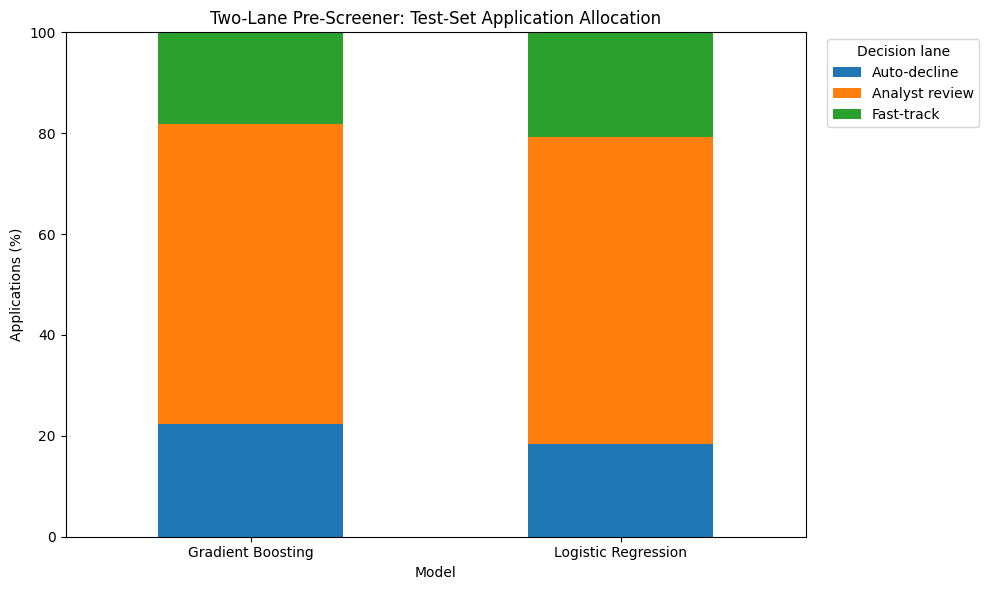

,Auto-decline,Analyst review,Fast-track
Gradient Boosting,22.29,59.46,18.25
Logistic Regression,18.33,61.00,20.67


In [62]:

import matplotlib.pyplot as plt

lane_order = ["Auto-decline", "Analyst review", "Fast-track"]
plot_data = {}

for model_name, lanes in test_lane_results.items():
    plot_data[model_name] = [
        (lanes == lane_name).mean() * 100
        for lane_name in lane_order
    ]

if plot_data:
    plot_df = pd.DataFrame(
        plot_data,
        index=lane_order
    ).T

    ax = plot_df.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 6)
    )

    ax.set_title("Two-Lane Pre-Screener: Test-Set Application Allocation")
    ax.set_xlabel("Model")
    ax.set_ylabel("Applications (%)")
    ax.set_ylim(0, 100)
    ax.legend(title="Decision lane", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    display(plot_df.round(2))
else:
    print("No model produced a threshold pair meeting both validation risk limits.")


In [63]:

MONTHLY_APPLICATIONS = 3000
MINUTES_PER_REVIEW = 25

monthly_impact_rows = []

for model_name, lanes in test_lane_results.items():
    auto_count = int((lanes == "Auto-decline").sum())
    fast_count = int((lanes == "Fast-track").sum())
    manual_count = int((lanes == "Analyst review").sum())

    auto_share = auto_count / len(lanes)
    fast_share = fast_count / len(lanes)
    manual_share = manual_count / len(lanes)

    # Calculate test-set error risks
    actual = np.asarray(y_test)

    auto_mask = lanes == "Auto-decline"
    fast_mask = lanes == "Fast-track"

    auto_risk = (
        (actual[auto_mask] == 0).mean() * 100
        if auto_mask.any() else np.nan
    )
    fast_risk = (
        (actual[fast_mask] == 1).mean() * 100
        if fast_mask.any() else np.nan
    )

    both_lanes_pass = (
        auto_mask.any()
        and fast_mask.any()
        and auto_risk <= RISK_LIMIT
        and fast_risk <= RISK_LIMIT
    )

    monthly_auto = round(MONTHLY_APPLICATIONS * auto_share)
    monthly_fast = round(MONTHLY_APPLICATIONS * fast_share)
    monthly_manual = round(MONTHLY_APPLICATIONS * manual_share)

    monthly_avoided = monthly_auto + monthly_fast
    hours_released = monthly_avoided * MINUTES_PER_REVIEW / 60

    monthly_impact_rows.append({
        "Model": model_name,
        "Monthly auto-declines (est.)": monthly_auto,
        "Monthly fast-tracks (est.)": monthly_fast,
        "Monthly manual reviews (est.)": monthly_manual,
        "Potential reviews avoided": monthly_avoided,
        "Potential hours released": round(hours_released, 1),
        "Test auto-decline risk (%)": round(auto_risk, 2),
        "Test fast-track risk (%)": round(fast_risk, 2),
        "Both test risks within 5%": both_lanes_pass
    })

monthly_impact = pd.DataFrame(monthly_impact_rows)
display(monthly_impact)

# Compare workload reduction against Logistic Regression
if len(monthly_impact) >= 2:
    impact_by_model = monthly_impact.set_index("Model")

    if (
        best_model_name in impact_by_model.index
        and "Logistic Regression" in impact_by_model.index
    ):
        difference_apps = (
            impact_by_model.loc[
                best_model_name, "Potential reviews avoided"
            ]
            - impact_by_model.loc[
                "Logistic Regression", "Potential reviews avoided"
            ]
        )

        difference_hours = difference_apps * MINUTES_PER_REVIEW / 60

        print(
            f"\n{best_model_name} vs Logistic Regression:"
        )
        print(
            "Difference in applications moved out of manual review per month:",
            int(difference_apps)
        )
        print(
            "Difference in potential analyst hours per month:",
            round(difference_hours, 1)
        )


,Model,Monthly auto-declines (est.),Monthly fast-tracks (est.),Monthly manual reviews (est.),Potential reviews avoided,Potential hours released,Test auto-decline risk (%),Test fast-track risk (%),Both test risks within 5%
0,Gradient Boosting,669,548,1784,1217,507.1,3.93,5.25,False
1,Logistic Regression,550,620,1830,1170,487.5,5.00,7.86,False



Gradient Boosting vs Logistic Regression:
Difference in applications moved out of manual review per month: 47
Difference in potential analyst hours per month: 19.6


### Monthly Business Impact

Using 3,000 applications a month and 25 minutes per manual review, Gradient Boosting would move about 1,217 applications a month out of manual review, releasing roughly 507 analyst hours. Logistic Regression would move about 1,170 applications, releasing roughly 488 hours, so the difference is 47 applications and about 20 analyst hours a month.

However, neither model passes both 5% limits on the held-out test set. Gradient Boosting's auto-decline lane passes at 3.93%, but its fast-track lane fails at 5.25%. Logistic Regression's auto-decline lane sits exactly at the limit (5.00%), and its fast-track lane fails at 7.86%. These savings are therefore estimates, and only lanes that pass on test should be considered for deployment.


## 5.11   Recommendation to the Credit Policy Analyst

## Credit Policy Recommendation

I recommend Gradient Boosting for further validation because it achieved a mean five-fold ROC-AUC of 0.887, compared with 0.867 for Logistic Regression. The proposed approval-probability thresholds are below 0.19 for auto-decline and above 0.86 for fast-track, with the remaining applications sent to analysts. On the held-out test set, Gradient Boosting assigned 22.29% of applications to auto-decline and 18.25% to fast-track, potentially moving approximately 1,217 applications per month out of manual review and releasing 507 analyst hours. However, the fast-track lane had a 5.25% error rate, exceeding the bank's 5% risk limit, so the complete two-lane design is not yet acceptable for deployment. The auto-decline lane alone had a 3.93% wrong-decline rate, potentially avoiding 669 manual reviews and releasing approximately 279 analyst hours monthly, but this also requires prospective validation and human oversight. Applicants in the Long-Term Job Applicants segment, which had the highest observed test error rate, and applicants with FOIR above 55% should receive additional human review. Historical approval rates differed by gender, and the Logistic Regression baseline also showed different auto-decline rates by gender; the bank should monitor outcomes and proxy-variable effects regularly. Before full rollout, validate the thresholds on fresh, representative applications and confirm that both automated lanes meet the 5% risk limits.


## 5.12 Stretch (Optional): Where Does the Model Struggle?

In this section, I used K-Means clustering to identify groups of applicants with similar income, credit score, FOIR, employment tenure, and age. I scaled these variables before clustering and used an elbow plot to help select the number of segments. I then assigned business-friendly names to the segments and examined their sizes, historical approval rates, and the selected model's error rates on the held-out test data. Cluster labels were used only for post-model analysis and were not added to the model's predictors.


In [64]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Features used ONLY for applicant segmentation
cluster_features = [
    "monthly_income",
    "credit_score",
    "foir",
    "years_in_current_job",
    "age"
]

# Use the cleaned dataframe from Part 1
cluster_df = df[cluster_features].copy()

# Convert clustering features to numeric values
for col in cluster_features:
    cluster_df[col] = pd.to_numeric(
        cluster_df[col], errors="coerce"
    )

# Impute missing values and scale features
cluster_imputer = SimpleImputer(strategy="median")
cluster_scaler = StandardScaler()

cluster_imputed = cluster_imputer.fit_transform(cluster_df)
cluster_scaled = cluster_scaler.fit_transform(cluster_imputed)

print("Rows used for clustering:", len(cluster_df))
print("Features used:", cluster_features)
print("Missing values after imputation:",
      pd.DataFrame(cluster_imputed, columns=cluster_features).isna().sum().sum())


Rows used for clustering: 12000
Features used: ['monthly_income', 'credit_score', 'foir', 'years_in_current_job', 'age']
Missing values after imputation: 0


/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_k

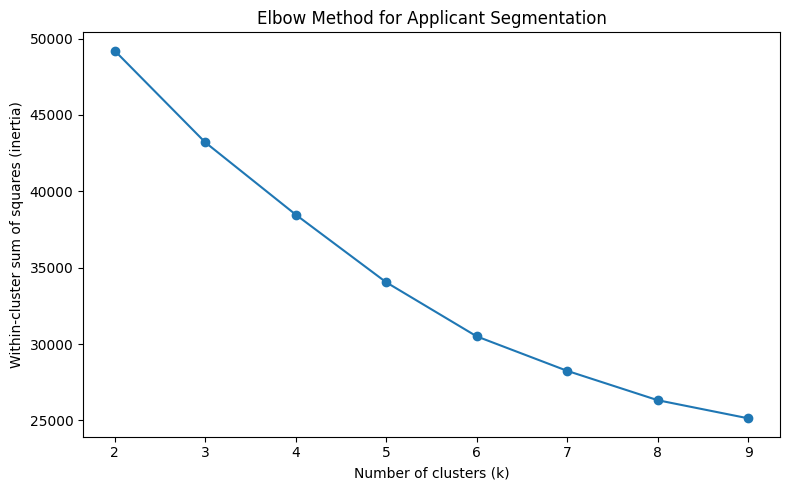

In [65]:

inertia_values = []
k_values = range(2, 10)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(cluster_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.title("Elbow Method for Applicant Segmentation")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squares (inertia)")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()


### Choosing the Number of Applicant Segments

The elbow plot shows inertia falling steadily without a sharp bend. The largest drop is from 2 to 3 clusters (about 6,000), after which the decrease slows to about 4,700 from 3 to 4 clusters, about 4,400 from 4 to 5, and about 3,500 from 5 to 6. Because there is no clear elbow, I chose k = 4 on interpretability: it is the smallest number of clusters at which each segment has a distinct profile in income, credit score, FOIR and tenure, and each segment is large enough for a reliable test-set error rate. The choice is a judgement that should be validated before it is used in policy.


In [66]:

chosen_k = 4

kmeans_final = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(cluster_scaled)


cluster_results = df.copy()
cluster_results["cluster"] = cluster_labels


cluster_profile = cluster_results.groupby("cluster").agg(
    applicant_count=("cluster", "size"),
    monthly_income_median=("monthly_income", "median"),
    credit_score_median=("credit_score", "median"),
    foir_median=("foir", "median"),
    job_tenure_median=("years_in_current_job", "median"),
    age_median=("age", "median")
)

display(cluster_profile.round(2))


/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_k

,applicant_count,monthly_income_median,credit_score_median,foir_median,job_tenure_median,age_median
cluster,,,,,,
0,3810,53250.0,773.0,0.28,2.7,35.0
1,2011,66500.0,716.0,0.30,8.0,40.0
2,4475,43500.0,687.0,0.29,2.1,28.0
3,1704,50000.0,726.0,0.66,2.8,33.0


In [67]:

# Rank clusters by their median income, credit score and FOIR
# to support consistent, data-informed naming.
cluster_profile["income_rank"] = cluster_profile[
    "monthly_income_median"
].rank(ascending=False, method="dense")

cluster_profile["credit_rank"] = cluster_profile[
    "credit_score_median"
].rank(ascending=False, method="dense")

cluster_profile["foir_rank"] = cluster_profile[
    "foir_median"
].rank(ascending=True, method="dense")

# Default neutral names; replace after reviewing the profiles.
business_names = {
    cluster_id: f"Applicant Segment {cluster_id + 1}"
    for cluster_id in cluster_profile.index
}

print("Review the profile table before assigning final business names.")
display(cluster_profile.round(2))


Review the profile table before assigning final business names.


,applicant_count,monthly_income_median,credit_score_median,foir_median,job_tenure_median,age_median,income_rank,credit_rank,foir_rank
cluster,,,,,,,,,
0,3810,53250.0,773.0,0.28,2.7,35.0,2.0,1.0,1.0
1,2011,66500.0,716.0,0.30,8.0,40.0,1.0,3.0,3.0
2,4475,43500.0,687.0,0.29,2.1,28.0,4.0,4.0,2.0
3,1704,50000.0,726.0,0.66,2.8,33.0,3.0,2.0,4.0


In [68]:
# Business names assigned from the cluster profiles above
# (cluster IDs are arbitrary, so the names are tied to each cluster's median profile)
business_names = {
    0: "High Approval Applicants",
    1: "Long-Term Job Applicants",
    2: "Young, Low-Income Applicants",
    3: "High Repayment-Burden Applicants",
}
cluster_results["segment_name"] = cluster_results["cluster"].map(business_names)

cluster_results["historical_approved"] = (
    cluster_results["decision"].astype(str).str.strip().str.lower() == "approved"
).astype(int)

segment_summary = cluster_results.groupby(["cluster", "segment_name"]).agg(
    applicant_count=("cluster", "size"),
    approval_rate=("historical_approved", "mean"),
    median_income=("monthly_income", "median"),
    median_credit_score=("credit_score", "median"),
    median_foir=("foir", "median"),
    median_job_tenure=("years_in_current_job", "median"),
    median_age=("age", "median")
).reset_index()
segment_summary["approval_rate"] *= 100
display(segment_summary.round(2))

,cluster,segment_name,applicant_count,approval_rate,median_income,median_credit_score,median_foir,median_job_tenure,median_age
0,0,High Approval Applicants,3810,79.08,53250.0,773.0,0.28,2.7,35.0
1,1,Long-Term Job Applicants,2011,58.58,66500.0,716.0,0.30,8.0,40.0
2,2,"Young, Low-Income Applicants",4475,42.01,43500.0,687.0,0.29,2.1,28.0
3,3,High Repayment-Burden Applicants,1704,16.55,50000.0,726.0,0.66,2.8,33.0


In [69]:

from sklearn.metrics import accuracy_score

# Align test rows to the cluster labels assigned to the original dataframe.
# This assumes X_test retains the original dataframe indices.
test_cluster_ids = cluster_results.loc[X_test.index, "cluster"]

test_segment_results = pd.DataFrame({
    "cluster": test_cluster_ids.to_numpy(),
    "actual": np.asarray(y_test),
    "predicted": np.asarray(best_model.predict(X_test))
}, index=X_test.index)

test_segment_results["error"] = (
    test_segment_results["actual"]
    != test_segment_results["predicted"]
).astype(int)

test_segment_summary = test_segment_results.groupby(
    "cluster"
).agg(
    test_applications=("error", "size"),
    model_errors=("error", "sum"),
    error_rate=("error", "mean")
).reset_index()

test_segment_summary["error_rate"] *= 100

test_segment_summary["segment_name"] = (
    test_segment_summary["cluster"].map(business_names)
)

test_segment_summary = test_segment_summary[
    [
        "cluster", "segment_name", "test_applications",
        "model_errors", "error_rate"
    ]
]

display(test_segment_summary.round(2))


,cluster,segment_name,test_applications,model_errors,error_rate
0,0,High Approval Applicants,774,146,18.86
1,1,Long-Term Job Applicants,396,94,23.74
2,2,"Young, Low-Income Applicants",881,202,22.93
3,3,High Repayment-Burden Applicants,349,52,14.90


In [70]:

final_segment_report = segment_summary.merge(
    test_segment_summary[
        ["cluster", "test_applications", "model_errors", "error_rate"]
    ],
    on="cluster",
    how="left"
)

final_segment_report = final_segment_report.rename(columns={
    "applicant_count": "Total Applicants",
    "approval_rate": "Approval Rate (%)",
    "test_applications": "Test Applicants",
    "model_errors": "Test Model Errors",
    "error_rate": "Test Error Rate (%)"
})

display(final_segment_report.round(2))


,cluster,segment_name,Total Applicants,Approval Rate (%),median_income,median_credit_score,median_foir,median_job_tenure,median_age,Test Applicants,Test Model Errors,Test Error Rate (%)
0,0,High Approval Applicants,3810,79.08,53250.0,773.0,0.28,2.7,35.0,774,146,18.86
1,1,Long-Term Job Applicants,2011,58.58,66500.0,716.0,0.30,8.0,40.0,396,94,23.74
2,2,"Young, Low-Income Applicants",4475,42.01,43500.0,687.0,0.29,2.1,28.0,881,202,22.93
3,3,High Repayment-Burden Applicants,1704,16.55,50000.0,726.0,0.66,2.8,33.0,349,52,14.90


### Which Segment Should Always Stay with a Human Analyst?

Long-Term Job Applicants should always stay with a human analyst. This segment has the highest test error rate of the four (23.74%, or 94 of 396 test applications), and its historical approval rate is 58.58%, so decisions are close to balanced and the model's signal is weakest there. The model gives little credit for tenure: years_in_current_job has an importance of only about 0.02, even though this segment's median tenure is eight years. Young, Low-Income Applicants (22.93% error on 881 test applications) should be monitored as a close second. The High Repayment-Burden segment has the lowest error rate (14.90%) because its approval rate is only 16.55%, so its declines are the easiest for the model to get right, but its median FOIR of 0.66 is well above the 55% line I propose for human review.
